## LSTM Autoencoder

Encoder LSTM compresses the 365-day ride series into a fixed-size latent vector.
Decoder LSTM reconstructs the sequence from the latent.
Input: MinMax-scaled rides per station, shape `(1, 365)`.

## 1. Setup & Data Prep

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output
from dotenv import load_dotenv
from sklearn.preprocessing import MinMaxScaler
from sklearn.manifold import TSNE

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from divvy_demand.infra.s3_client import S3Client

load_dotenv('../../.env')
s3 = S3Client(env='prod')

station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])
print('Station table:', station.shape)
station.head()

Station table: (1404660, 7)


,date,start_station_name,start_station_id,total_rides,ebike_rides,member_rides,casual_rides
0,2020-01-01,63rd St Beach,101,2,0,2,0
1,2020-01-01,900 W Harrison St,109,1,0,1,0
2,2020-01-01,Aberdeen St & Jackson Blvd,21,2,0,2,0
3,2020-01-01,Aberdeen St & Monroe St,80,7,0,7,0
4,2020-01-01,Aberdeen St & Randolph St,621,3,0,3,0


In [12]:
# Use 2023 — full year, dense signal
df = station[station['date'].dt.year == 2023].copy()

pivot_full = (
    df.groupby(['start_station_name', 'date'])['total_rides']
    .sum()
    .unstack('date')
    .fillna(0)
)
print(f'All stations: {pivot_full.shape[0]}, Days: {pivot_full.shape[1]}')

All stations: 1593, Days: 365


In [13]:
MIN_ACTIVE_DAYS = 7
pivot = pivot_full[(pivot_full > 0).sum(axis=1) >= MIN_ACTIVE_DAYS]
print(f'Stations kept (>= {MIN_ACTIVE_DAYS} active days): {len(pivot)} / {len(pivot_full)}')
dates = pivot.columns

Stations kept (>= 7 active days): 1301 / 1593


## 2. Feature Engineering

In [14]:
# MinMax scale each station to [0, 1]
rides_scaled = MinMaxScaler().fit_transform(pivot.T).T  # (n_stations, n_days)

n_stations, n_days = rides_scaled.shape
print(f'Shape: {rides_scaled.shape}  range [{rides_scaled.min():.2f}, {rides_scaled.max():.2f}]')

Shape: (1301, 365)  range [0.00, 1.00]


In [15]:
# LSTM expects (batch, seq_len, input_size) — shape: (n_stations, 365, 1)
X = rides_scaled[:, :, None].astype('float32')  # (n_stations, 365, 1)

np.random.seed(42)
idx = np.random.permutation(n_stations)
split = int(0.8 * n_stations)
train_idx, val_idx = idx[:split], idx[split:]

X_tensor = torch.tensor(X, dtype=torch.float32)
X_train  = X_tensor[train_idx]
X_val    = X_tensor[val_idx]

train_loader = DataLoader(TensorDataset(X_train), batch_size=64, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val),   batch_size=64, shuffle=False)

print(f'X: {X.shape}  Train: {len(X_train)}  Val: {len(X_val)}')

X: (1301, 365, 1)  Train: 1040  Val: 261


## 3. Model Architecture

In [16]:
SEQ_LEN    = n_days        # 365
INPUT_SIZE = 1             # rides channel
HIDDEN     = 64            # LSTM hidden size
LATENT_DIM = 32            # bottleneck — final latent vector size
NUM_LAYERS = 2             # stacked LSTM layers


class LSTMAutoencoder(nn.Module):
    def __init__(self, input_size, hidden, latent_dim, num_layers, seq_len):
        super().__init__()
        self.seq_len   = seq_len
        self.hidden    = hidden
        self.num_layers = num_layers

        # Encoder: LSTM processes the full sequence, final hidden state → latent
        self.encoder_lstm = nn.LSTM(
            input_size, hidden, num_layers,
            batch_first=True, dropout=0.1 if num_layers > 1 else 0.0
        )
        self.enc_proj = nn.Linear(hidden, latent_dim)   # (hidden,) → (latent_dim,)
        self.latent_norm = nn.LayerNorm(latent_dim)

        # Decoder: project latent → hidden, then LSTM reconstructs sequence
        self.dec_proj = nn.Linear(latent_dim, hidden)
        self.decoder_lstm = nn.LSTM(
            hidden, hidden, num_layers,
            batch_first=True, dropout=0.1 if num_layers > 1 else 0.0
        )
        self.out_proj = nn.Linear(hidden, input_size)   # → sigmoid for [0,1]

    def encode(self, x):
        # x: (B, T, 1)
        _, (h, _) = self.encoder_lstm(x)   # h: (num_layers, B, hidden)
        h_top = h[-1]                       # top layer: (B, hidden)
        return self.latent_norm(self.enc_proj(h_top))   # (B, latent_dim)

    def decode(self, z):
        # z: (B, latent_dim)
        h0 = self.dec_proj(z)                           # (B, hidden)
        # Repeat latent as input to decoder LSTM at every time step
        dec_input = h0.unsqueeze(1).expand(-1, self.seq_len, -1)  # (B, T, hidden)
        out, _ = self.decoder_lstm(dec_input)           # (B, T, hidden)
        return torch.sigmoid(self.out_proj(out))        # (B, T, 1)

    def forward(self, x):
        return self.decode(self.encode(x))


model = LSTMAutoencoder(INPUT_SIZE, HIDDEN, LATENT_DIM, NUM_LAYERS, SEQ_LEN)
with torch.no_grad():
    dummy = torch.zeros(2, SEQ_LEN, INPUT_SIZE)
    z   = model.encode(dummy)
    out = model.decode(z)
    print(f'Input:  {tuple(dummy.shape)}')
    print(f'Latent: {tuple(z.shape)}  — {z.shape[1]}-dim vector per station')
    print(f'Output: {tuple(out.shape)}  {"✓" if out.shape == dummy.shape else "✗ mismatch"}')
    print(f'Params: {sum(p.numel() for p in model.parameters()):,}')

Input:  (2, 365, 1)
Latent: (2, 32)  — 32-dim vector per station
Output: (2, 365, 1)  ✓
Params: 121,313


## 4. Training (live loss plot)

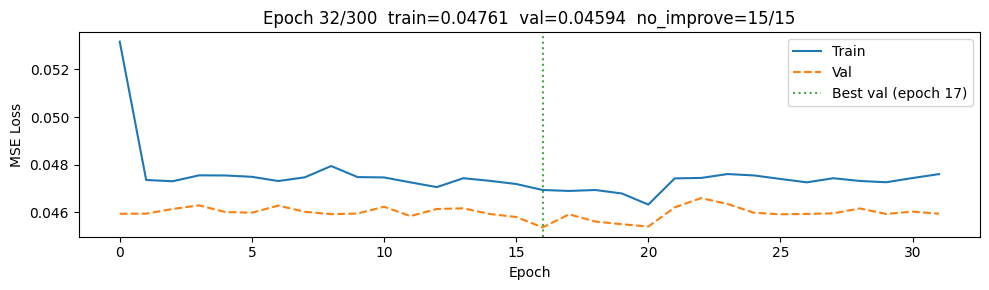

Early stopping at epoch 32 — no val improvement for 15 epochs
Restored best model (val=0.045367)


In [ ]:
EPOCHS    = 300
LR        = 1e-3
PATIENCE   = 15
MIN_DELTA  = 1e-6
WEIGHT_DECAY = 1e-4  # L2 regularisation

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')

model = LSTMAutoencoder(INPUT_SIZE, HIDDEN, LATENT_DIM, NUM_LAYERS, SEQ_LEN).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
criterion = nn.MSELoss()

train_losses, val_losses = [], []
best_val   = float('inf')
best_state = None
no_improve = 0

for epoch in range(1, EPOCHS + 1):
    # --- train ---
    model.train()
    t_loss = 0
    for (batch,) in train_loader:
        batch = batch.to(device)
        loss  = criterion(model(batch), batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        t_loss += loss.item() * len(batch)
    train_losses.append(t_loss / len(X_train))

    # --- val ---
    model.eval()
    v_loss = 0
    with torch.no_grad():
        for (batch,) in val_loader:
            batch  = batch.to(device)
            v_loss += criterion(model(batch), batch).item() * len(batch)
    val_losses.append(v_loss / len(X_val))

    # --- early stopping ---
    if val_losses[-1] < best_val - MIN_DELTA:
        best_val   = val_losses[-1]
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        no_improve = 0
    else:
        no_improve += 1

    # --- live plot every 5 epochs ---
    if epoch % 5 == 0 or epoch == 1 or no_improve == PATIENCE:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(10, 3))
        ax.plot(train_losses, label='Train')
        ax.plot(val_losses,   label='Val', linestyle='--')
        ax.axvline(len(val_losses) - no_improve - 1, color='green',
                   linestyle=':', alpha=0.7, label=f'Best val (epoch {len(val_losses)-no_improve})')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('MSE Loss')
        ax.set_title(f'Epoch {epoch}/{EPOCHS}  train={train_losses[-1]:.5f}  val={val_losses[-1]:.5f}  no_improve={no_improve}/{PATIENCE}')
        ax.legend()
        plt.tight_layout()
        plt.show()

    if no_improve >= PATIENCE:
        print(f'Early stopping at epoch {epoch} — no val improvement for {PATIENCE} epochs')
        break

model.load_state_dict(best_state)
print(f'Restored best model (val={best_val:.6f})')

## 5. Reconstruction Check

In [18]:
model.eval()
with torch.no_grad():
    # X_tensor: (n_stations, 365, 1) — LSTM format
    X_recon = model(X_tensor.to(device)).cpu().numpy()   # (n_stations, 365, 1)
    Z       = model.encode(X_tensor.to(device)).cpu().numpy()  # (n_stations, latent_dim)

recon_error = np.mean((X[:, :, 0] - X_recon[:, :, 0]) ** 2, axis=1)
print(f'Mean MSE: {recon_error.mean():.5f}')
print(f'Worst 5 stations:')
for i in np.argsort(recon_error)[-5:][::-1]:
    print(f'  {pivot.index[i]}: {recon_error[i]:.5f}')

Mean MSE: 0.04713
Worst 5 stations:
  Kingsbury St & Kinzie St: 0.18108
  State St & Chicago Ave: 0.17599
  Clinton St & Washington Blvd: 0.14731
  Wolcott Ave & Polk St: 0.14665
  Canal St & Adams St: 0.14543


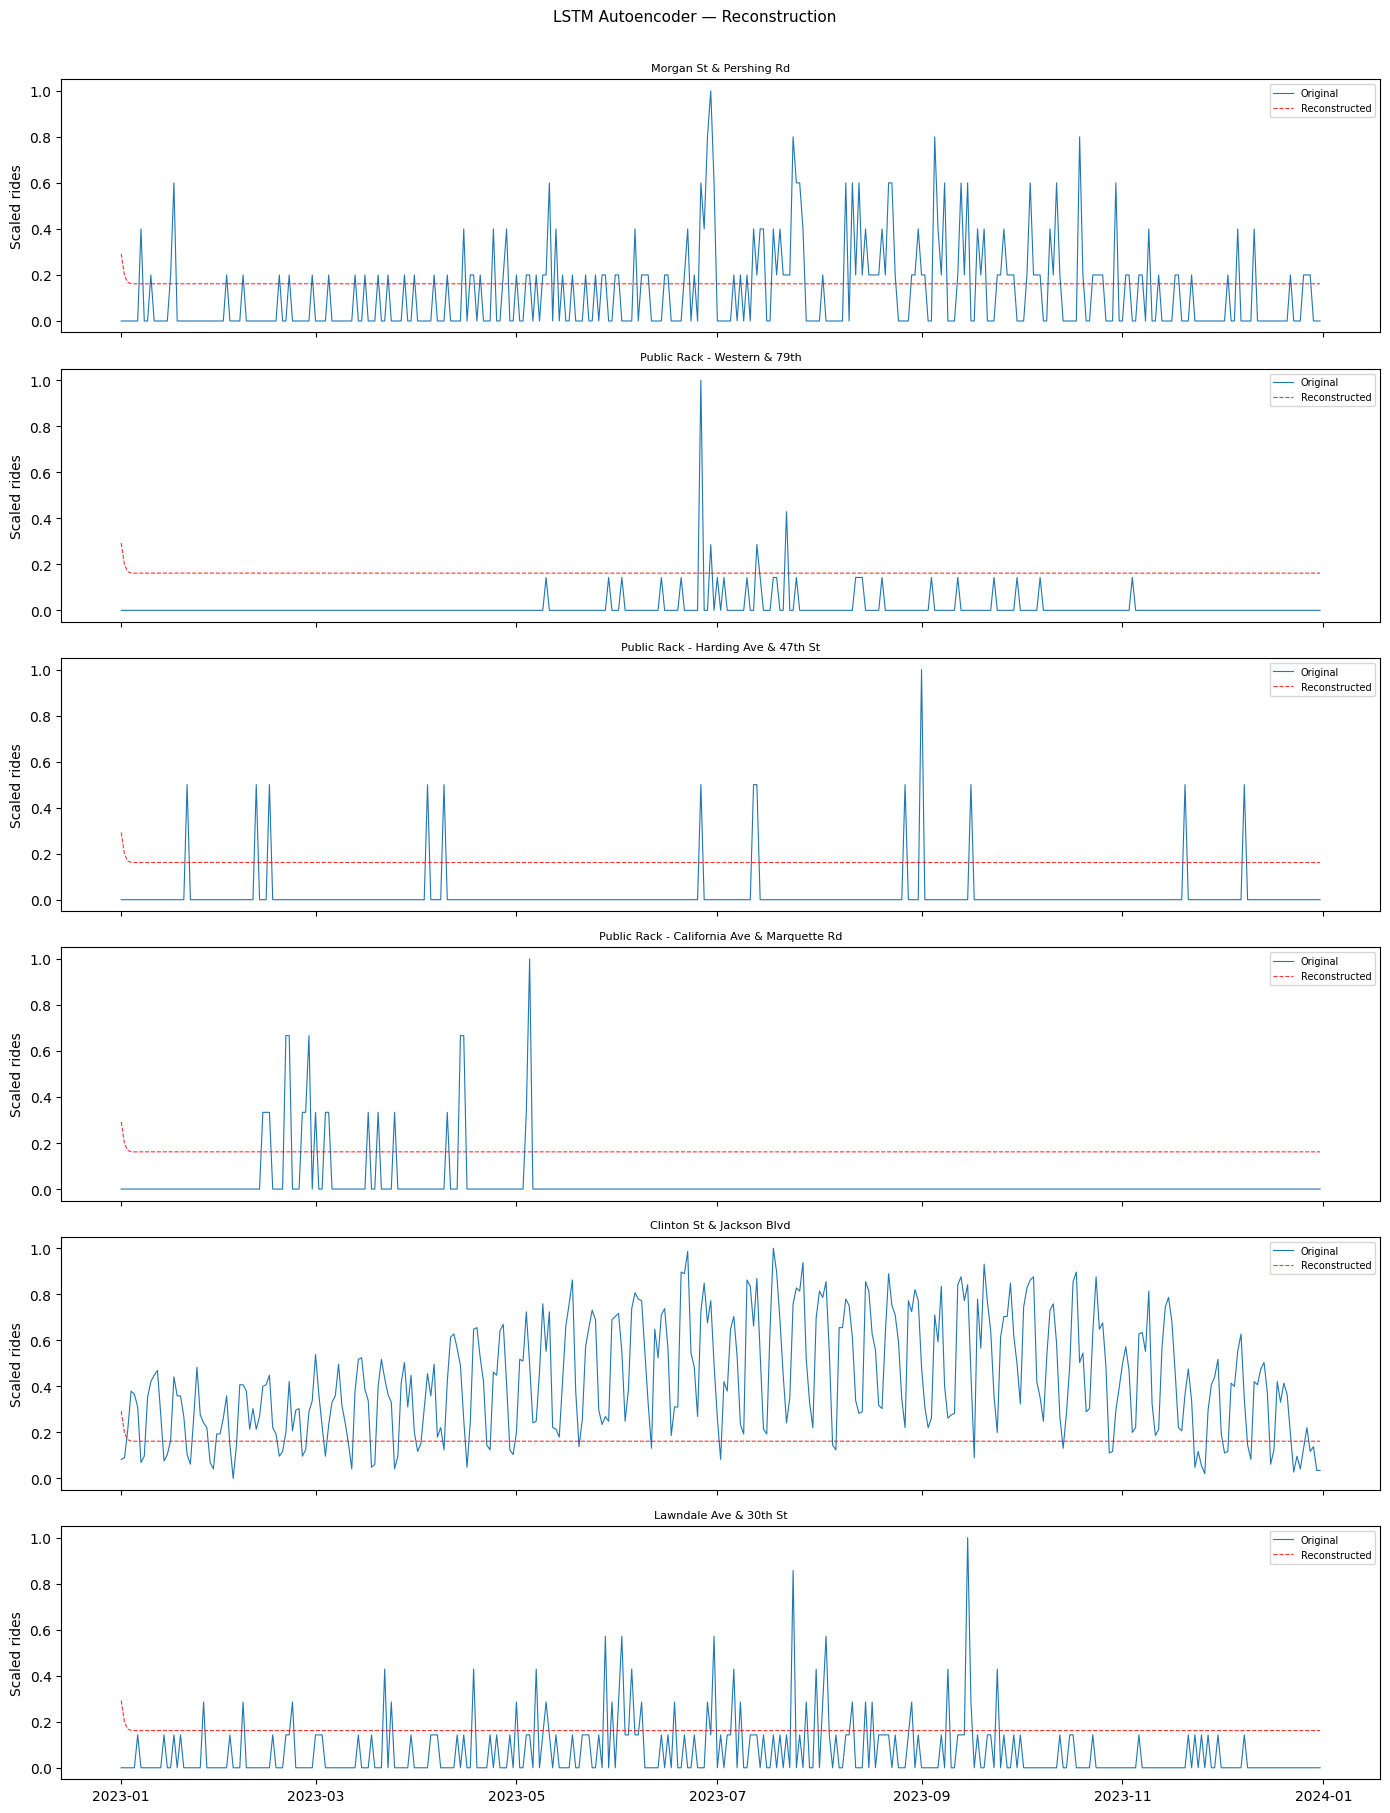

In [19]:
# Plot original vs reconstruction — 6 random stations
np.random.seed(0)
sample_idx = np.random.choice(n_stations, 6, replace=False)

fig, axes = plt.subplots(6, 1, figsize=(14, 18), sharex=True)
for ax, idx in zip(axes, sample_idx):
    ax.plot(dates, X[idx, :, 0], label='Original', linewidth=0.8)
    ax.plot(dates, X_recon[idx, :, 0], label='Reconstructed', linewidth=0.8,
            linestyle='--', color='red', alpha=0.8)
    ax.set_title(pivot.index[idx], fontsize=8)
    ax.set_ylabel('Scaled rides')
    ax.legend(fontsize=7)
fig.suptitle('LSTM Autoencoder — Reconstruction', fontsize=11, y=1.005)
plt.tight_layout()
plt.show()

## 6. Latent Space — t-SNE

In [20]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
Z_2d = tsne.fit_transform(Z)  # (n_stations, 2)

# Color by mean ride volume
mean_rides = pivot.values.mean(axis=1)

fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(Z_2d[:, 0], Z_2d[:, 1], c=mean_rides, cmap='YlOrRd',
                s=12, alpha=0.7, linewidths=0)
plt.colorbar(sc, ax=ax, label='Mean daily rides')
ax.set_title(f't-SNE of LSTM Latent Space ({LATENT_DIM}-dim → 2D)  |  n={len(Z)} stations')
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
plt.tight_layout()
plt.show()

TypeError: TSNE.__init__() got an unexpected keyword argument 'n_iter'